In [1]:
import pandas as pd
import numpy as np
import ipaddress

file_path = '../data/raw/cicids2017/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv' # Thay bằng file thực tế
chunk_size = 100000
sampled_chunks = []

# Định nghĩa tỷ lệ lấy mẫu cho lớp Benign (ví dụ: giữ lại 10%)
benign_sample_rate = 0.10

for chunk in pd.read_csv(file_path, chunksize=chunk_size, low_memory=False):
    # Tách chunk thành 2 phần: Benign và các loại khác
    benign_data = chunk[chunk[' Label'] == 'BENIGN']
    attack_data = chunk[chunk[' Label'] != 'BENIGN']
    
    # Lấy mẫu ngẫu nhiên lớp Benign
    benign_sampled = benign_data.sample(frac=benign_sample_rate, random_state=42)
    
    # Gộp lại và đưa vào danh sách
    sampled_chunks.append(pd.concat([benign_sampled, attack_data]))

# Ghép tất cả các chunk đã lấy mẫu thành một DataFrame duy nhất
df = pd.concat(sampled_chunks, ignore_index=True)
print(f"Kích thước dữ liệu sau khi lấy mẫu: {df.shape}")

Kích thước dữ liệu sau khi lấy mẫu: (137799, 85)


In [3]:
import pandas as pd
import numpy as np
import glob
import os

# 1. Đường dẫn tới thư mục chứa tất cả các file CSV
# (Nếu bạn bị lỗi FileNotFoundError, hãy đổi '../data/raw/cicids2017/' thành 'data/raw/cicids2017/')
folder_path = '../data/raw/cicids2017/' 
all_files = glob.glob(os.path.join(folder_path, "*.csv"))

print(f"Tìm thấy {len(all_files)} file CSV. Đang bắt đầu quá trình đọc và lấy mẫu...")

chunk_size = 100000
benign_sample_rate = 0.10 # Giữ lại 10% traffic bình thường
sampled_chunks = []

# 2. Vòng lặp tự động đi qua từng file một
for file in all_files:
    print(f"Đang xử lý: {os.path.basename(file)}...")
    
    # Đọc từng chunk trong file
    # Thêm tham số encoding='cp1252' vào hàm đọc CSV
    for chunk in pd.read_csv(file, chunksize=chunk_size, low_memory=False, encoding='cp1252'):
        
        # Xóa khoảng trắng ở tên cột trước để gọi nhãn không bị lỗi KeyError
        chunk.columns = chunk.columns.str.strip()
        
        # Kiểm tra xem có cột 'Label' không (phòng trường hợp file trắng)
        if 'Label' in chunk.columns:
            # Tách dữ liệu
            benign_data = chunk[chunk['Label'] == 'BENIGN']
            attack_data = chunk[chunk['Label'] != 'BENIGN']
            
            # Lấy mẫu ngẫu nhiên cho lớp Benign
            benign_sampled = benign_data.sample(frac=benign_sample_rate, random_state=42)
            
            # Đưa vào danh sách gộp
            sampled_chunks.append(pd.concat([benign_sampled, attack_data]))

# 3. Gộp tất cả dữ liệu từ mọi file lại thành một bảng duy nhất
df = pd.concat(sampled_chunks, ignore_index=True)

# 4. Tiếp tục làm sạch cơ bản (chuẩn hóa chữ thường tên cột, xóa NaN)
df.columns = df.columns.str.lower().str.replace(' ', '_')
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

print("--------------------------------------------------")
print(f"✅ Hoàn thành! Kích thước dữ liệu tổng cộng: {df.shape}")
print("Phân phối các nhãn tấn công trong tập dữ liệu tổng:")
print(df['label'].value_counts())

Tìm thấy 8 file CSV. Đang bắt đầu quá trình đọc và lấy mẫu...
Đang xử lý: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv...
Đang xử lý: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv...
Đang xử lý: Friday-WorkingHours-Morning.pcap_ISCX.csv...
Đang xử lý: Monday-WorkingHours.pcap_ISCX.csv...
Đang xử lý: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv...
Đang xử lý: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv...
Đang xử lý: Tuesday-WorkingHours.pcap_ISCX.csv...
Đang xử lý: Wednesday-workingHours.pcap_ISCX.csv...
--------------------------------------------------
✅ Hoàn thành! Kích thước dữ liệu tổng cộng: (783678, 85)
Phân phối các nhãn tấn công trong tập dữ liệu tổng:
label
DoS Hulk                      230123
BENIGN                        227123
PortScan                      158804
DDoS                          128025
DoS GoldenEye                  10293
FTP-Patator                     7935
SSH-Patator                     5897
DoS slowloris               

In [4]:
import pandas as pd
import ipaddress

print("Bắt đầu thực hiện Bước 3 & Bước 4...")

# =====================================================================
# BƯỚC 3: CHUẨN HÓA IP VÀ TIMESTAMP (Chuẩn bị tạo Dimension)
# =====================================================================

# Hàm kiểm tra IP nội bộ
def is_private_ip(ip_str):
    try:
        return ipaddress.ip_address(ip_str).is_private
    except ValueError:
        return False

print("Đang chuẩn hóa IP...")
# Kiểm tra xem tên cột IP trong file của bạn là gì (có thể là source_ip hoặc bỗng dưng viết hoa)
# Thường sau khi đổi chữ thường ở Bước 2, nó sẽ là 'source_ip' và 'destination_ip'
if 'source_ip' in df.columns:
    df['is_internal_src'] = df['source_ip'].apply(is_private_ip)
if 'destination_ip' in df.columns:
    df['is_internal_dst'] = df['destination_ip'].apply(is_private_ip)

print("Đang chuẩn hóa Timestamp...")
if 'timestamp' in df.columns:
    # Chuyển đổi cẩn thận về định dạng Datetime
    df['timestamp'] = pd.to_datetime(df['timestamp'], format='mixed', dayfirst=True, errors='coerce')
    # Bỏ các dòng không thể parse được thời gian
    df.dropna(subset=['timestamp'], inplace=True)


# =====================================================================
# BƯỚC 4: GỘP NHÓM NHÃN TẤN CÔNG (Quyết định phạm vi đề tài)
# =====================================================================

def map_attack_group(label):
    label = str(label).upper()
    if label == 'BENIGN':
        return 'Benign'
    elif 'DDOS' in label or 'DOS' in label:
        return 'DDoS'
    elif 'PORTSCAN' in label:
        return 'PortScan'
    elif 'WEB ATTACK' in label:
        return 'WebAttack'
    elif 'BOT' in label:
        return 'Botnet'
    else:
        return 'Other'

print("Đang gộp nhóm nhãn tấn công...")
df['attack_group'] = df['label'].apply(map_attack_group)

print("--------------------------------------------------")
print("✅ ĐÃ CHUẨN HÓA XONG TOÀN BỘ!")
print("Thống kê phân bố nhãn theo nhóm Attack Group:")
print(df['attack_group'].value_counts())

Bắt đầu thực hiện Bước 3 & Bước 4...
Đang chuẩn hóa IP...
Đang chuẩn hóa Timestamp...
Đang gộp nhóm nhãn tấn công...
--------------------------------------------------
✅ ĐÃ CHUẨN HÓA XONG TOÀN BỘ!
Thống kê phân bố nhãn theo nhóm Attack Group:
attack_group
DDoS         379736
Benign       227123
PortScan     158804
Other         13879
WebAttack      2180
Botnet         1956
Name: count, dtype: int64


Đang vẽ biểu đồ...


C:\Users\Admin\AppData\Local\Temp\ipykernel_25244\4102988696.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='attack_group', order=df['attack_group'].value_counts().index, palette='viridis')


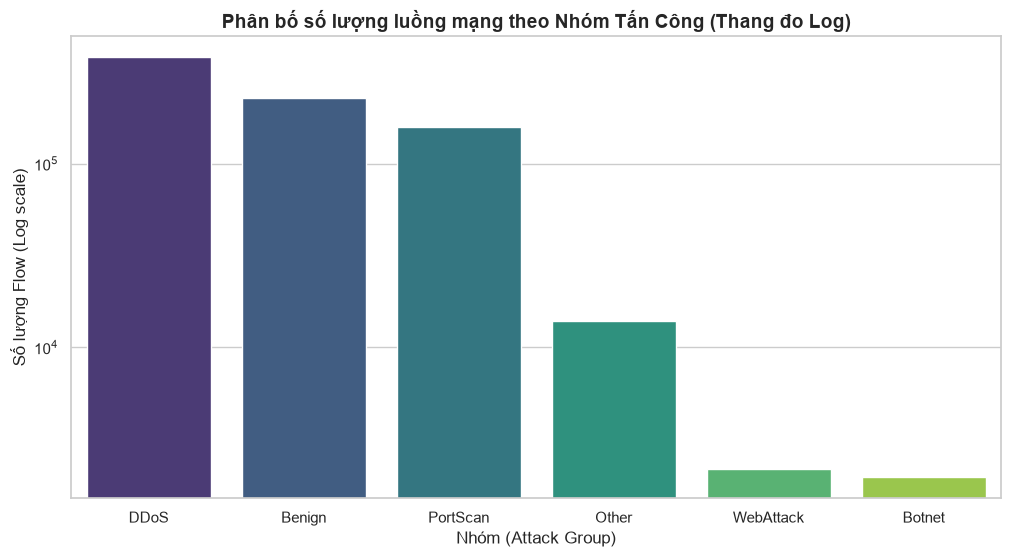

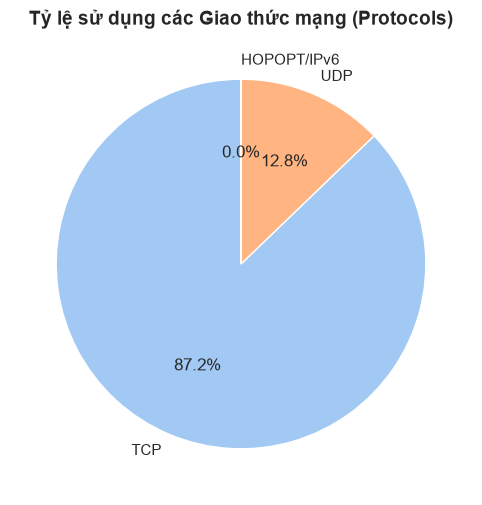

Đã tìm thấy cột đo lường: total_length_of_fwd_packets


C:\Users\Admin\AppData\Local\Temp\ipykernel_25244\4102988696.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=byte_stats.index, y=byte_stats.values, palette='magma')


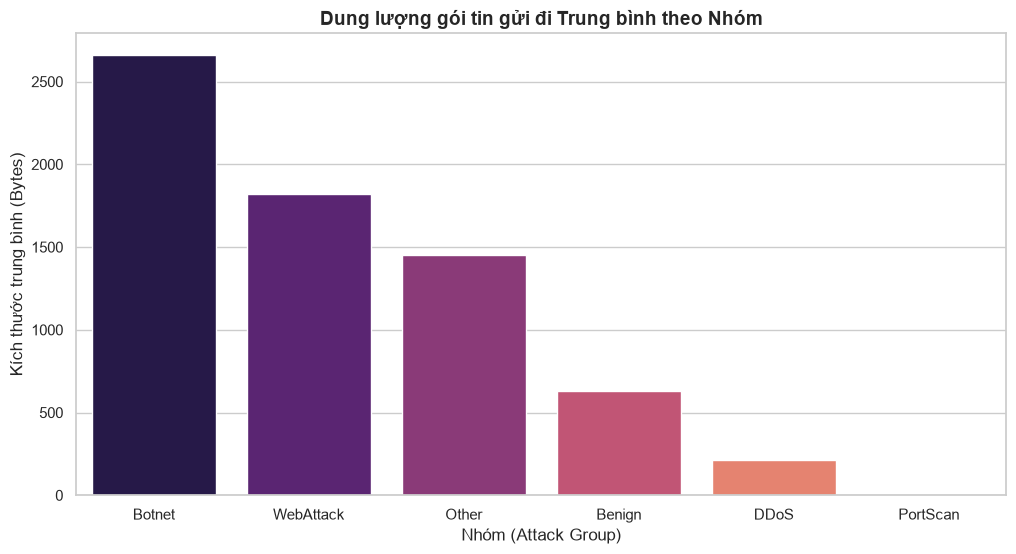

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập phong cách cho biểu đồ đẹp hơn
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("Đang vẽ biểu đồ...")

# =====================================================================
# Biểu đồ 1: Phân bố các nhóm tấn công (Class Distribution)
# =====================================================================
plt.figure()
# Dùng thang đo Logarit (log scale) vì lớp Benign thường áp đảo hoàn toàn (hàng triệu) 
# so với các lớp tấn công (vài nghìn/chục nghìn)
ax = sns.countplot(data=df, x='attack_group', order=df['attack_group'].value_counts().index, palette='viridis')
plt.title('Phân bố số lượng luồng mạng theo Nhóm Tấn Công (Thang đo Log)', fontsize=14, fontweight='bold')
plt.yscale('log') 
plt.ylabel('Số lượng Flow (Log scale)')
plt.xlabel('Nhóm (Attack Group)')
plt.show()

# =====================================================================
# Biểu đồ 2: Phân bố giao thức mạng (Protocol)
# (Trong CICIDS2017: 6 là TCP, 17 là UDP, 0 hoặc 1 là ICMP)
# =====================================================================
plt.figure()
protocol_counts = df['protocol'].value_counts()
# Đổi số thành tên cho dễ nhìn
protocol_map = {6: 'TCP', 17: 'UDP', 0: 'HOPOPT/IPv6', 1: 'ICMP'}
protocol_labels = [protocol_map.get(p, str(p)) for p in protocol_counts.index]

plt.pie(protocol_counts, labels=protocol_labels, autopct='%1.1f%%', startangle=90, colors=sns.color_palette('pastel'))
plt.title('Tỷ lệ sử dụng các Giao thức mạng (Protocols)', fontsize=14, fontweight='bold')
plt.show()

# =====================================================================
# =====================================================================
# Biểu đồ 3: Lưu lượng băng thông (Total Bytes) trung bình của từng nhóm
# =====================================================================
plt.figure()

# Tự động quét và tìm tên cột có chứa cả chữ 'length' và chữ 'fwd'
byte_col = next((col for col in df.columns if 'length' in col and 'fwd' in col), None)

if byte_col:
    print(f"Đã tìm thấy cột đo lường: {byte_col}")
    
    # Tính trung bình số Byte truyền tải theo từng nhóm tấn công
    byte_stats = df.groupby('attack_group')[byte_col].mean().sort_values(ascending=False)
    
    sns.barplot(x=byte_stats.index, y=byte_stats.values, palette='magma')
    plt.title('Dung lượng gói tin gửi đi Trung bình theo Nhóm', fontsize=14, fontweight='bold')
    plt.ylabel('Kích thước trung bình (Bytes)')
    plt.xlabel('Nhóm (Attack Group)')
    plt.show()
else:
    print("⚠️ Không tìm thấy cột đo lường dung lượng gói tin trong bộ dữ liệu này.")

In [6]:
print(df.columns.tolist())


['destination_port', 'flow_duration', 'total_fwd_packets', 'total_backward_packets', 'total_length_of_fwd_packets', 'total_length_of_bwd_packets', 'fwd_packet_length_max', 'fwd_packet_length_min', 'fwd_packet_length_mean', 'fwd_packet_length_std', 'bwd_packet_length_max', 'bwd_packet_length_min', 'bwd_packet_length_mean', 'bwd_packet_length_std', 'flow_bytes/s', 'flow_packets/s', 'flow_iat_mean', 'flow_iat_std', 'flow_iat_max', 'flow_iat_min', 'fwd_iat_total', 'fwd_iat_mean', 'fwd_iat_std', 'fwd_iat_max', 'fwd_iat_min', 'bwd_iat_total', 'bwd_iat_mean', 'bwd_iat_std', 'bwd_iat_max', 'bwd_iat_min', 'fwd_psh_flags', 'bwd_psh_flags', 'fwd_urg_flags', 'bwd_urg_flags', 'fwd_header_length', 'bwd_header_length', 'fwd_packets/s', 'bwd_packets/s', 'min_packet_length', 'max_packet_length', 'packet_length_mean', 'packet_length_std', 'packet_length_variance', 'fin_flag_count', 'syn_flag_count', 'rst_flag_count', 'psh_flag_count', 'ack_flag_count', 'urg_flag_count', 'cwe_flag_count', 'ece_flag_count

In [7]:
# Lưu dữ liệu đã làm sạch vào thư mục processed
df.to_csv('../data/processed/cleaned_cicids2017.csv', index=False)
print("Đã lưu dữ liệu làm sạch thành công!")

Đã lưu dữ liệu làm sạch thành công!
